In [30]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

sz = qt.sigmaz()
sm = qt.sigmam()
sp = qt.sigmap()
sx = qt.sigmax()

pi = np.pi
f_drive = 8e9
c = 3e8
er = 6.38
vp = c / np.sqrt(er)
lambda_drive = vp / f_drive

0.00044934824109077454
471118055.38973266
Gamma =  7554554554.554555


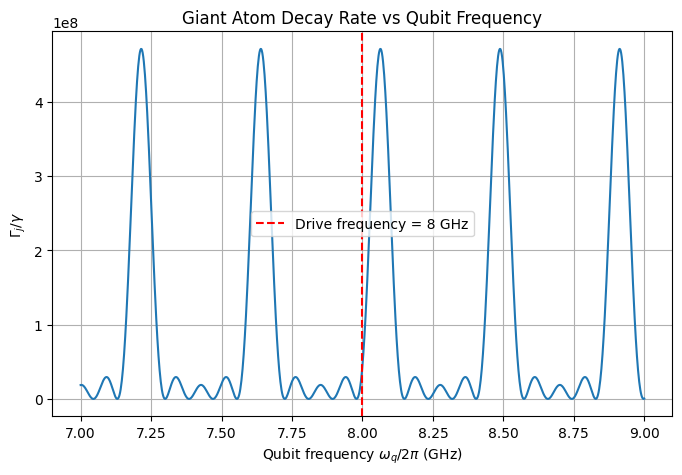

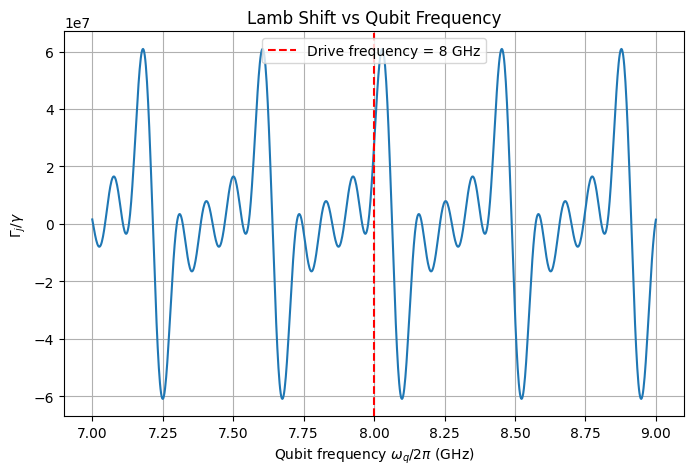

In [36]:
### showing via Kockum Decoherence Free gamma equation with N=1 (giant atoms), M=5 (coupling points)

def param_calc(f_q):
    
    vp = c / np.sqrt(er) # phase velocity of drive
    lambda_drive = vp / f_drive # wavelength of drive
    L = 3 * lambda_drive / 2 # length between points bc drive frequency is fixed

    lambda_q = f_q / vp # wavelength of qubit
    w_q = 2 * pi * f_q # qubit freq

    gamma = 2* pi * 3.0e6 # gamma ~ 3 MHz
    # gamma = 1
    Gamma = np.zeros_like(w_q, dtype=float)
    lamb_shift =  np.zeros_like(w_q, dtype=float)

    phi_0 = L * w_q / vp
    phis = np.array([i * 2*phi_0 for i in range(5)])

    for i in range(5):
        for j in range(5):
            phi_ij = phis[i] - phis[j]
            Gamma += gamma * np.cos(phi_ij)

    for i in range(4):
            for j in range(5):
                phi_ij = phis[i] - phis[j]
                lamb_shift += gamma * np.sin(phi_ij)

    return Gamma, lamb_shift

freq_q = np.linspace(7e9, 9e9, 1000)
omega_q = 2 * pi * freq_q

Gamma, lamb_shift = param_calc(omega_q)


Gamma_zeros = np.min(Gamma)
print(Gamma_zeros)
print(np.max(Gamma))
index = np.argmin(Gamma)
print("Gamma = ", freq_q[index])

plt.figure(figsize=(8, 5))
plt.plot(freq_q / 1e9, Gamma)
plt.axvline(8, color='red', linestyle='--',
            label='Drive frequency = 8 GHz')

plt.xlabel(r'Qubit frequency $\omega_q/2\pi$ (GHz)')
plt.ylabel(r'$\Gamma_j/\gamma$')
plt.title('Giant Atom Decay Rate vs Qubit Frequency')
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(freq_q / 1e9, lamb_shift)
plt.axvline(8, color='red', linestyle='--',
            label='Drive frequency = 8 GHz')

plt.xlabel(r'Qubit frequency $\omega_q/2\pi$ (GHz)')
plt.ylabel(r'$\Gamma_j/\gamma$')
plt.title('Lamb Shift vs Qubit Frequency')
plt.grid(True)
plt.legend()
plt.show()

[14.49182293 14.49182293]
Gamma =  [7.46646647e+09 8.53353353e+09]
8533533533.533533


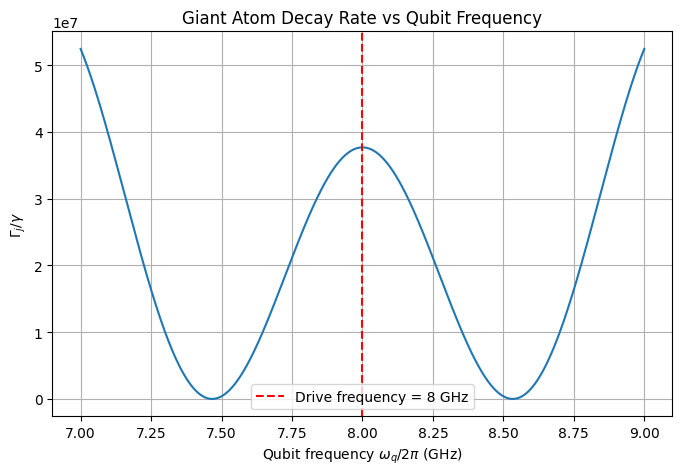

In [32]:
### Alejandro Gamma equation
from scipy.signal import find_peaks

def param_calc_new(f_q):
    vp = c / np.sqrt(er)
    lambda_drive = vp / f_drive
    L = 3 * lambda_drive / 2 # length between points bc drive frequency is fixed
    gamma = 3e6
    lambda_q = f_q / vp
    w_q = 2 * pi * f_q

    gamma = 2* pi * 3.0e6 # gamma ~ 3 MHz
    phi_i = w_q * L / vp
    Gamma = np.zeros_like(w_q, dtype=float)
    # lamb_shift =  np.zeros_like(w_q, dtype=float)

    phi_0 = L * w_q / vp
    Gamma = 2 * gamma * np.square((1 + (2*np.cos(phi_i)) + 2*(np.cos(2*phi_i))))

    # phis = np.array([i * phi_0 for i in range(5)])

    # for i in range(5):
    #         Gamma += 2 * gamma * np.square(1 + 2 * np.cos(phis[i]) + 2 * np.cos(2*phis[i]) )
    

    return Gamma

Gamma_new = param_calc_new(freq_q)
# Gamma_zeros_new = np.min(Gamma_new)
# print(Gamma_zeros_new)
# print(np.max(Gamma_new))
# index = np.argmin(Gamma_new)
# print("Gamma = ", freq_q[index])

minima_indices = find_peaks(-Gamma_new)[0]
local_minima = Gamma_new[minima_indices]
print(local_minima)
print("Gamma = ", freq_q[minima_indices])
print(freq_q[minima_indices][1])

plt.figure(figsize=(8, 5))
plt.plot(freq_q / 1e9, Gamma_new)

plt.axvline(8, color='red', linestyle='--',
            label='Drive frequency = 8 GHz')
# plt.axvline(freq_q[minima_indices][0], color='red', linestyle='--',
#              label='Drive frequency = '' GHz')
# plt.axvline(8, color='red', linestyle='--',
#             label='Drive frequency = 8 GHz')

plt.xlabel(r'Qubit frequency $\omega_q/2\pi$ (GHz)')
plt.ylabel(r'$\Gamma_j/\gamma$')
plt.title('Giant Atom Decay Rate vs Qubit Frequency')
plt.grid(True)
plt.legend()
plt.show()





In [33]:
# New param calc from Alejandro

# def param_calc(f_q):
#     L = 3 * lambda_drive / 2 # length between points bc drive frequency is fixed

#     lambda_q = f_q / vp
#     w_q = 2 * pi * f_q

#     gamma = 2* pi * 3.0e6 # gamma ~ 3 MHz
#     # gamma = 1
#     Gamma = np.zeros_like(w_q, dtype=float)
#     lamb_shift =  np.zeros_like(w_q, dtype=float)

#     phi_0 = L * w_q / vp;
#     phis = np.array([i * phi_0 for i in range(5)])

#     for i in range(5):
#         for j in range(5):
#             phi_ij = phis[i] - phis[j]
#             Gamma += gamma * np.cos(phi_ij)

#     for i in range(4):
#             for j in range(5):
#                 phi_ij = phis[i] - phis[j]
#                 lamb_shift += gamma * np.sin(phi_ij)

#     return Gamma, lamb_shift

# freq_q = np.linspace(7e9, 9e9, 1000)
# omega_q = 2 * pi * freq_q

# Gamma, lamb_shift = param_calc(omega_q)


# Gamma_zeros = np.min(Gamma)
# print(Gamma_zeros)
# print(np.max(Gamma))
# index = np.argmin(Gamma)
# print(freq_q[index])

# plt.figure(figsize=(8, 5))
# plt.plot(freq_q / 1e9, Gamma)
# plt.axvline(8, color='red', linestyle='--',
#             label='Drive frequency = 8 GHz')

# plt.xlabel(r'Qubit frequency $\omega_q/2\pi$ (GHz)')
# plt.ylabel(r'$\Gamma_j/\gamma$')
# plt.title('Giant Atom Decay Rate vs Qubit Frequency')
# plt.grid(True)
# plt.legend()
# plt.show()

# plt.figure(figsize=(8, 5))
# plt.plot(freq_q / 1e9, lamb_shift)
# plt.axvline(8, color='red', linestyle='--',
#             label='Drive frequency = 8 GHz')

# plt.xlabel(r'Qubit frequency $\omega_q/2\pi$ (GHz)')
# plt.ylabel(r'$\Gamma_j/\gamma$')
# plt.title('Lamb Shift vs Qubit Frequency')
# plt.grid(True)
# plt.legend()
# plt.show()

Gamma/2pi = 0.0000 MHz
Delta/2pi = -533.5371 MHz
Omega/2pi = 7.9577 MHz
Omega_R/2pi = 533.5964 MHz


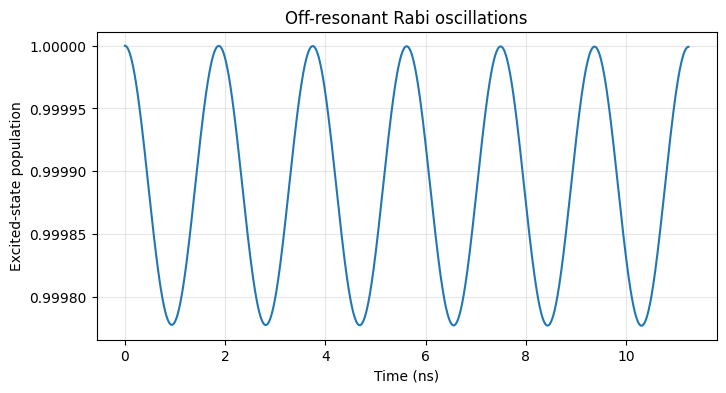

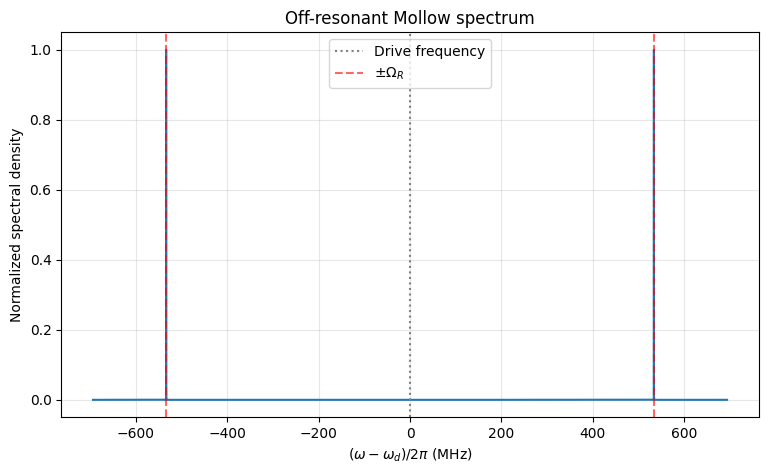

In [ ]:
# f_q = 7978978978.978979
# f_q = 7554554554.554555
import numpy as np
f_q = 7.46646647e+09
# Giant atom decay and Lamb shift
# Assumes outputs are angular frequencies in rad/s
Gres, ls_res = param_calc_new(f_q)

Gres = float(np.asarray(Gres).item())
ls_res = float(np.asarray(ls_res).item())

if Gres <= 0:
    raise ValueError("Gres must be positive.")

omega_q = 2 * pi * f_q + ls_res
omega_d = 2 * pi * f_drive

Delta = omega_q - omega_d

Omega = 50e6

Omega_R = np.sqrt(Omega**2 + Delta**2)

print(f"Gamma/2pi = {Gres/(2*pi*1e6):.4f} MHz")
print(f"Delta/2pi = {Delta/(2*pi*1e6):.4f} MHz")
print(f"Omega/2pi = {Omega/(2*pi*1e6):.4f} MHz")
print(f"Omega_R/2pi = {Omega_R/(2*pi*1e6):.4f} MHz")

# Rescale to rad/microsecond
# Time unit is now microseconds

scale = 1e6

gamma = Gres / scale
delta = Delta / scale
omega_rabi = Omega / scale
omega_R = Omega_R / scale

# Rotating-frame Hamiltonian
H = delta/2 * sz + omega_rabi/2 * sx

# Collapse operator
c_ops = [np.sqrt(gamma) * sm]

# Time evolution

psi0 = qt.basis(2, 0)
n_exc = sp * sm

# Several generalized Rabi periods
T_R = 2 * pi / omega_R
tlist = np.linspace(0, 6 * T_R, 2000)

result = qt.mesolve(
    H,
    psi0,
    tlist,
    c_ops=c_ops,
    e_ops=[n_exc]
)

plt.figure(figsize=(8, 4))
plt.plot(tlist * 1e3, result.expect[0])
plt.xlabel("Time (ns)")
plt.ylabel("Excited-state population")
plt.title("Off-resonant Rabi oscillations")
plt.grid(alpha=0.3)
plt.show()

# Mollow spectrum
# Include both generalized-Rabi sidebands

wmax = 1.3 * omega_R + 8 * gamma

wlist = np.linspace(-wmax, wmax, 16001)

S = qt.spectrum(H, wlist, c_ops, sp, sm)
S = np.maximum(np.real(S), 0.0)

# Frequency offsets from drive, in MHz
freq_MHz = wlist / (2 * pi)
sideband_MHz = omega_R / (2 * pi)

# Normalize to peak
S_norm = S / np.max(S)

# Linear spectrum
plt.figure(figsize=(9, 5))

plt.plot(freq_MHz, S_norm, linewidth=1.5)

plt.axvline(0, color="gray", linestyle=":",
            label="Drive frequency")

plt.axvline(-sideband_MHz, color="red",
            linestyle="--", alpha=0.6,
            label=r"$\pm \Omega_R$")

plt.axvline(sideband_MHz, color="red",
            linestyle="--", alpha=0.6)

plt.xlabel(r"$(\omega-\omega_d)/2\pi$ (MHz)")
plt.ylabel("Normalized spectral density")
plt.title("Off-resonant Mollow spectrum")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
